## Sampling Bias and Sample Size

### 1. Introduction

Sampling helps us understand a population by studying a smaller group of observations. However, the conclusions we draw depend on how the sample is selected and how much information it contains.

Two important questions are:

Is the sample reliable and representative of the population?

Is the sample large enough for the analysis?

In this notebook, we will study sampling errors, different types of sampling bias, sample size, and the effect of sample size on statistical estimates.

We will use a Student Performance dataset to explore these concepts practically.

### 2. Sampling Error vs. Non-Sampling Error

#### Sampling Error

Sampling error is the difference between a sample statistic and the corresponding population parameter because only a subset of the population was observed.

Example: The average math score of 100 sampled students is 68, while the average of all students is 70.

The difference is:

Sampling error = Sample mean − Population mean

#### Non-Sampling Error

Non-sampling errors arise from problems other than selecting a sample instead of studying the entire population.

Examples:
- Incorrect data entry
- Missing responses
- Incorrect measurements
- Ambiguous survey questions
- Data collection mistakes

#### Key Difference

Sampling error can occur even when random sampling is performed correctly. Non-sampling errors can occur in both samples and censuses.

**Important:** A larger sample generally reduces random sampling variability, but it does not automatically eliminate bias or data-quality problems.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\Cloud Nine\Documents\Shalini\stats and probability\StudentsPerformance.csv")

# Population mean using all available records
population_mean = df["math score"].mean()

# Select a random sample
sample = df.sample(n=min(100, len(df)), random_state=42)

sample_mean = sample["math score"].mean()

sampling_error = sample_mean - population_mean

print("Population mean:", population_mean)
print("Sample mean:", sample_mean)
print("Sampling error:", sampling_error)
print("Absolute sampling error:", abs(sampling_error))

Population mean: 66.089
Sample mean: 63.95
Sampling error: -2.138999999999996
Absolute sampling error: 2.138999999999996


The sample mean may differ from the population mean because the sample includes only some observations.

The signed sampling error indicates the direction of the difference:
- Positive: the sample mean is higher.
- Negative: the sample mean is lower.
- Zero: both means are equal.

Here, the complete dataset acts as our reference population for the exercise. In real research, the true population mean is often unknown.

### 3. Sampling Bias


Sampling bias occurs when the method used to select observations systematically favours certain members of the population over others.

#### Example

Suppose a college surveys only students who attend morning classes to understand the study habits of all students. Students attending afternoon or evening classes are excluded.

The selected sample may not reflect the entire student population.

#### Intuition

Sampling error is about the difference that can arise from studying a subset. Sampling bias is about a systematic problem in how that subset is selected.

A larger sample does not necessarily fix sampling bias. If the same groups continue to be excluded, the results may remain misleading.

#### Common Causes

- Selecting only easily accessible participants
- Excluding certain population groups
- Relying on voluntary responses
- Using incomplete sampling frames

In [3]:
# Random sample
random_sample = df.sample(
    n=min(100, len(df)),
    random_state=42
)

# Convenience-style sample: first available rows
convenience_sample = df.head(min(100, len(df)))

print("Full dataset mean:",
      df["math score"].mean())

print("Random sample mean:",
      random_sample["math score"].mean())

print("Convenience sample mean:",
      convenience_sample["math score"].mean())

Full dataset mean: 66.089
Random sample mean: 63.95
Convenience sample mean: 60.63


The means may differ between the random sample and the convenience sample.

However, a difference alone does not prove sampling bias. The ordering of rows in the dataset may or may not be related to student performance. We need to understand how the data was collected and organised before concluding that a sample is biased.


### 4. Random Sampling vs. Biased Sampling


#### Random Sampling

Random sampling uses a random selection mechanism. In simple random sampling, every possible sample of a specified size has an equal chance of being selected.

#### Biased Sampling

Biased sampling occurs when the selection process systematically favours or excludes particular observations.

#### Comparison

| Random Sampling | Biased Sampling |
|---|---|
| Uses a random selection process | Selection systematically favours certain observations |
| Supports statistical inference when the design and assumptions are appropriate | Can produce systematically misleading estimates |
| Can still produce a sample that differs from the population | Increasing sample size alone may not remove the bias |

**Remember:** Random sampling does not guarantee that every selected sample perfectly represents the population. It helps control systematic selection problems and allows sampling uncertainty to be studied.

### 5. Representativeness of a Sample

A sample is representative when it reflects the relevant characteristics of the target population for the purpose of the study.

For example, if a student population contains different gender groups, a useful sample may need to reflect their distribution when gender is relevant to the research question.

Representativeness depends on:
- The sampling method
- The population being studied
- Which characteristics matter to the analysis
- Whether certain groups are missing or underrepresented

A sample does not need to match the population in every characteristic. It should adequately represent the characteristics relevant to the conclusions being drawn.

#### Important Distinction

A sample that matches the population on one variable may still differ on other variables.

In [4]:
population_gender = (
    df["gender"]
    .value_counts(normalize=True)
    .sort_index()
)

sample_gender = (
    random_sample["gender"]
    .value_counts(normalize=True)
    .sort_index()
)

gender_comparison = pd.DataFrame({
    "Population proportion": population_gender,
    "Sample proportion": sample_gender
}).fillna(0)

gender_comparison["Absolute difference"] = (
    gender_comparison["Sample proportion"]
    - gender_comparison["Population proportion"]
).abs()

gender_comparison

,Population proportion,Sample proportion,Absolute difference
gender,,,
female,0.518,0.48,0.038
male,0.482,0.52,0.038


Compare the population and sample proportions for each gender group.

Smaller differences indicate a closer match for this characteristic. Larger differences suggest that the sample composition differs from the full dataset.

This comparison evaluates representativeness only with respect to gender. It does not establish that the sample represents the population in every other respect.

### 6. Undercoverage Bias

Undercoverage bias occurs when some members or groups of the target population have little or no chance of being included in the sampling process.

#### Example

A survey about student internet access is conducted only through an online form. Students without reliable internet access may be less likely to participate or may be unable to access the survey.

As a result, the survey may fail to capture the experiences of the very group being studied.

#### How to Reduce It

- Use a sampling frame that covers the target population.
- Include alternative data collection methods when needed.
- Identify groups that are missing from the sampling frame.
- Compare sample coverage with known population information where available.

**Key idea:** Undercoverage is a problem with who can be selected, not merely how many people are selected.

In [5]:
# Illustrative example only:
# Suppose a researcher can access only one group.
# Replace "group" with a real population characteristic
# in a dataset where the missing group is known.

# Demonstrate undercoverage by excluding one gender group.
available_group = df[df["gender"] == "female"]

print("Full dataset size:", len(df))
print("Available group size:", len(available_group))

print("Full dataset mean math score:",
      df["math score"].mean())

print("Available group mean math score:",
      available_group["math score"].mean())

Full dataset size: 1000
Available group size: 518
Full dataset mean math score: 66.089
Available group mean math score: 63.633204633204635


This example deliberately excludes male students to illustrate undercoverage. It is not evidence that the original Student Performance dataset has undercoverage bias.

The mean from the restricted group describes that group, not necessarily the entire population. Whether this difference matters depends on the research question.

### 7. Nonresponse Bias

Nonresponse bias occurs when selected participants do not respond, and the people who respond differ systematically from those who do not.

#### Example

A college sends a satisfaction survey to all students, but students who are dissatisfied may be more likely to respond than satisfied students—or the reverse.

The responses may therefore give a misleading picture of overall satisfaction.

#### How to Reduce It

- Send reminders to selected participants.
- Make surveys easy to complete.
- Offer appropriate alternative response methods.
- Examine response rates across relevant groups.
- Use suitable statistical adjustments when the required information is available.

**Important:** Missing data does not automatically cause nonresponse bias. Bias is a concern when response behaviour is related to the characteristic being estimated.

In [6]:
# Illustrative simulation:
# Treat the first 30% of rows as respondents and the rest
# as nonrespondents. This is artificial, not actual survey data.

split_index = int(len(df) * 0.30)

respondents = df.iloc[:split_index].copy()
nonrespondents = df.iloc[split_index:].copy()

print("Total selected:", len(df))
print("Respondents:", len(respondents))
print("Nonrespondents:", len(nonrespondents))

print("\nMean math score:")
print("All selected:", df["math score"].mean())
print("Respondents:", respondents["math score"].mean())
print("Nonrespondents:", nonrespondents["math score"].mean())

Total selected: 1000
Respondents: 300
Nonrespondents: 700

Mean math score:
All selected: 66.089
Respondents: 65.61
Nonrespondents: 66.29428571428572


This simulation divides rows into two groups for comparison. It does not model real response behaviour, because the first 30% of rows are not necessarily actual respondents.

In a real survey, nonresponse bias should be investigated by examining whether respondents differ from nonrespondents on relevant characteristics, where such information is available.

### 8. Factors Affecting Sample Size

Sample size is the number of observations included in a sample.

The appropriate sample size depends on several factors:

1. **Population variability:** More variability generally requires a larger sample to estimate a population characteristic with the same precision.
2. **Confidence level:** A higher confidence level generally requires a larger sample.
3. **Margin of error:** A smaller acceptable margin of error requires a larger sample.
4. **Population size:** Population size matters, particularly when sampling without replacement from a finite population.
5. **Sampling design:** Clustered or complex samples may require more observations than a simple random sample.
6. **Available resources:** Time, cost, and accessibility can limit the sample size.

#### Intuition

If you want a more precise estimate, you generally need more information. However, the required sample size also depends on how variable the data is and how precisely you want to estimate the population characteristic.

### 9. Sample Size vs. Sampling Accuracy

Increasing sample size generally reduces random sampling variability when the sampling method and other conditions remain appropriate.

For estimating a population mean using independent observations with standard deviation \(\sigma\), the standard error is:

$$
SE(\bar{x})=\frac{\sigma}{\sqrt{n}}
$$


Where:

- $\sigma$ = Population standard deviation
- $n$ = Sample size
- $SE(\bar{x})$ = Standard error of the sample mean
  
#### Intuition

The standard error decreases in proportion to the square root of the sample size.

If the sample size increases fourfold, the standard error becomes approximately half as large, under the same assumptions.

**Important:** A larger biased sample can still give a biased estimate. Sample size improves precision; it does not automatically improve representativeness.

In [7]:
sample_sizes = [
    n for n in [10, 30, 50, 100, 200]
    if n <= len(df)
]

population_mean = df["math score"].mean()

results = []

for n in sample_sizes:
    sample = df.sample(n=n, random_state=42)

    sample_mean = sample["math score"].mean()

    results.append({
        "Sample Size": n,
        "Sample Mean": sample_mean,
        "Absolute Error": abs(sample_mean - population_mean)
    })

sample_size_results = pd.DataFrame(results)
sample_size_results

,Sample Size,Sample Mean,Absolute Error
0,10,72.400000,6.311000
1,30,61.033333,5.055667
2,50,62.680000,3.409000
3,100,63.950000,2.139000
4,200,64.460000,1.629000


Compare the sample means and absolute errors at different sample sizes.

Larger samples often provide more stable estimates, but the absolute error does not have to decrease every time the sample size increases. This code also uses the same random seed, so the samples are not independent across sample sizes.

The table illustrates one sequence of samples, not a guarantee that every larger sample will be more accurate.

### 10. Finite Population Correction (FPC)

The finite population correction adjusts the standard error when sampling without replacement from a finite population, particularly when the sample represents a substantial fraction of that population.

For a sample mean under simple random sampling without replacement:

$$
SE(\bar{x})=
\frac{\sigma}{\sqrt{n}}
\sqrt{\frac{N-n}{N-1}}
$$

Where:

- $n$ = Sample size
- $\sigma$ = Population standard deviation

The correction factor is:

$$
FPC = \sqrt{\frac{N-n}{N-1}}
$$

#### Intuition

When a large fraction of the population has already been observed, less uncertainty remains about the population mean.

- If \(n\) is small relative to \(N\), the correction factor is close to 1.
- As \(n\) approaches \(N\), the correction factor approaches 0.
- If the entire population is observed, there is no sampling uncertainty about its mean.

**Assumption:** This formula applies to simple random sampling without replacement; other sampling designs may need different variance calculations.

In [8]:
import numpy as np

N = len(df)       # Population size in this exercise
n = min(100, N)   # Sample size

if N > 1 and n <= N:
    fpc = np.sqrt((N - n) / (N - 1))

    population_std = df["math score"].std(ddof=0)

    se_without_fpc = population_std / np.sqrt(n)
    se_with_fpc = se_without_fpc * fpc

    print("Population size:", N)
    print("Sample size:", n)
    print("FPC:", fpc)
    print("SE without FPC:", se_without_fpc)
    print("SE with FPC:", se_with_fpc)
else:
    print("FPC calculation requires N > 1 and 1 <= n <= N.")

Population size: 1000
Sample size: 100
FPC: 0.949157995752499
SE without FPC: 1.5155496659628165
SE with FPC: 1.4384960834086362


#### Interpretation

The standard error with FPC is adjusted downward because the sample is drawn without replacement from a finite population.

In this exercise, the full dataset is treated as the population. In real studies, use the actual target population size and an appropriate estimate of its variability.

When sampling only a small fraction of a very large population, the correction is often negligible.

### 11. Repeated Sampling

A single sample shows only one possible outcome of the sampling process. Repeated sampling helps us understand how much a statistic can vary across different samples of the same size.

We will:
1. Draw multiple random samples.
2. Calculate the mean math score for each sample.
3. Compare the sample means with the population mean.
4. Observe the variability of the estimates.

This is a useful practical introduction to sampling distributions, which will be covered in the next notebook.

In [9]:
population_mean = df["math score"].mean()

n = min(100, len(df))
number_of_samples = 100

sample_means = []

for seed in range(number_of_samples):
    sample = df.sample(n=n, random_state=seed)
    sample_means.append(sample["math score"].mean())

repeated_sampling = pd.DataFrame({
    "Sample Number": range(1, number_of_samples + 1),
    "Sample Mean": sample_means
})

repeated_sampling["Absolute Error"] = (
    repeated_sampling["Sample Mean"] - population_mean
).abs()

print("Population mean:", population_mean)
print("Mean of sample means:", repeated_sampling["Sample Mean"].mean())
print("Standard deviation of sample means:",
      repeated_sampling["Sample Mean"].std())

repeated_sampling.head()

Population mean: 66.089
Mean of sample means: 66.0393
Standard deviation of sample means: 1.4482537412311074


,Sample Number,Sample Mean,Absolute Error
0,1,65.34,0.749
1,2,64.18,1.909
2,3,66.62,0.531
3,4,66.64,0.551
4,5,65.52,0.569


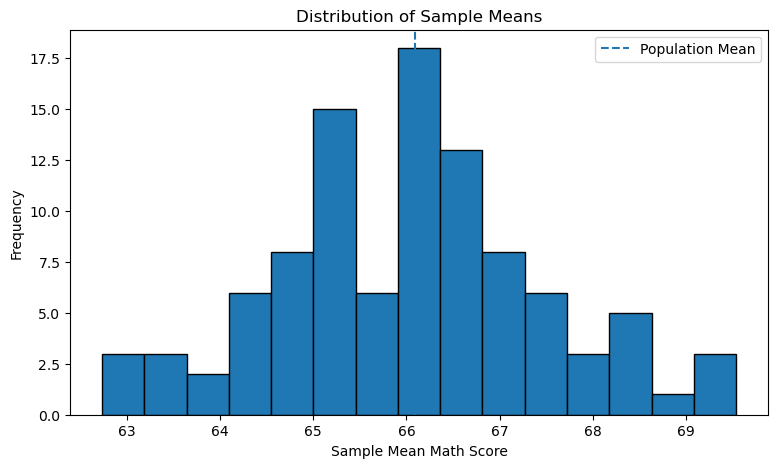

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    repeated_sampling["Sample Mean"],
    bins=15,
    edgecolor="black"
)

plt.axvline(
    population_mean,
    linestyle="--",
    label="Population Mean"
)

plt.title("Distribution of Sample Means")
plt.xlabel("Sample Mean Math Score")
plt.ylabel("Frequency")
plt.legend()
plt.show()

#### Interpretation

Each histogram value represents the mean from one random sample, not an individual student's score.

The sample means will generally vary around the population mean. Their spread shows how much the estimated mean changes across repeated samples.

The standard deviation of these sample means estimates the standard error for this repeated-sampling procedure. This experiment provides the foundation for understanding sampling distributions and the Central Limit Theorem in the next notebook.

### 12. Business Applications

Sampling bias and sample size matter in real business decisions.

#### Customer Satisfaction
If only highly engaged customers answer a survey, the results may not reflect all customers.

#### Product Quality
Inspecting a suitable sample of products can help estimate defect rates without inspecting every item.

#### Marketing Research
A survey that excludes certain customer groups may lead to misleading conclusions about market demand.

#### A/B Testing
The number of participants affects the precision of estimated differences between two versions of a product or campaign.

#### Business Takeaway
Before interpreting a statistic, check how the data was collected, which groups may be missing, and whether the sample size is adequate for the decision.

### 13. Machine Learning Connection

Sampling concepts also affect machine learning.

#### 1. Training Data Representativeness
If the training dataset excludes important user groups, the model may perform poorly on those groups.

#### 2. Train-Test Split
Random splitting can help create training and testing sets. However, the correct splitting strategy depends on the dataset and task.

#### 3. Stratified Splitting
Stratified splitting helps preserve class proportions across the training and testing sets, which is useful for classification when class proportions matter.

#### 4. Class Imbalance
When one class is rare, random sampling may produce too few examples of that class. Appropriate stratification or resampling techniques may help.

#### 5. Time-Series Data
Random splitting can cause data leakage when future observations influence evaluation on earlier periods. Time-ordered splitting is often more appropriate.

**Key idea:** A large dataset is not automatically a good dataset. Coverage, selection, data quality, and the evaluation strategy all matter.

### 14. Key Takeaways

- Sampling error arises because a sample is used to estimate a population characteristic.
- Non-sampling errors include measurement mistakes, missing responses, and data-entry errors.
- Sampling bias occurs when the selection process systematically favours or excludes certain population members.
- Representativeness depends on the target population and the characteristics relevant to the study.
- Undercoverage occurs when some population members cannot adequately enter the sample.
- Nonresponse bias can occur when respondents differ systematically from nonrespondents.
- Larger samples generally reduce random sampling variability, but they do not automatically eliminate bias.
- Sample size depends on variability, confidence level, desired precision, sampling design, and population size.
- Finite population correction adjusts standard error for sampling without replacement from a finite population.
- Repeated sampling helps us understand the variability of sample statistics.

#### Final Thought

A reliable analysis requires both **good-quality data and an appropriate sampling method**. Always examine how a sample was selected before trusting its conclusions.

Cluster sampling divides a population into natural groups called clusters.

Researchers randomly select some clusters and study the individuals within the selected clusters.

#### Example

A university has 50 classrooms.

Instead of randomly selecting individual students from every classroom, a researcher randomly selects five classrooms and studies the students in those classrooms.

Here:

- Population: All students in the university
- Clusters: Classrooms
- Selected clusters: Five classrooms
- Sample: Students belonging to the selected classrooms

#### When to Use It

- When individuals naturally belong to groups.
- When collecting data from selected groups is easier or cheaper.
- When studying geographically distributed populations.

#### Limitation

Selected clusters may differ from the overall population.

Cluster sampling requires genuine cluster identifiers, such as classroom, school, village, or branch.

**Dataset note:** If your Student Performance dataset does not contain a suitable cluster identifier, understand this method conceptually rather than inventing clusters.